# Week 6 — Query-Conditioned Passage Fidelity Routing

### Scientific Research Question
> **At a fixed high-fidelity representation budget $k$, can we improve SARA by choosing WHICH retrieved passages remain in full text instead of automatically keeping the first $k$ BM25-ranked passages?**

---

### Context & Transition from Weeks 3–5
- **Weeks 3–5 asked:** *HOW MANY* passages should remain in high fidelity? (Adaptive budget $k \in \{2, 4, 5, 6, 8\}$).
- **Week 6 asks:** *WHICH* passages deserve high fidelity at a fixed budget?
$$\boxed{\text{Hold } k \text{ fixed and change only passage identity selection.}}$$

Any downstream quality difference is thus strictly attributable to passage routing rather than context size.

### Primary Comparison Matrix
Three routing policies across fixed budgets $k \in \{2, 4, 6\}$:
1. **$R_0$ (BM25 Prefix Baseline):** Standard SARA default ($D_1 \dots D_k$ natural text, $D_{k+1} \dots D_{10}$ compressed).
2. **$R_1$ (Pretrained Semantic Top-$k$):** Frozen sentence-transformers MiniLM query-passage relevance, rendered in original BM25 rank order.
3. **$R_2$ (Learned Evidence Router):** Lightweight MLP over frozen MiniLM pair embeddings and weak retrieval rank prior, trained on QASPER gold evidence matching.


## 1. Environment & Setup

Imports canonical modules, loads configuration, sets random seeds, and creates output directory structure.


In [1]:
import os
import sys
import json
import time
import copy
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoTokenizer

# Resolve Project Root across any working directory (e.g. repo root or notebooks/week6)
_curr = Path.cwd().resolve()
candidates = [_curr, _curr.parent, _curr.parent.parent]
PROJECT_ROOT = next((p for p in candidates if (p / "src").is_dir() and (p / "configs").is_dir()), _curr)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

SARA_ROOT = PROJECT_ROOT / "Baselines/SARA-main"
if str(SARA_ROOT) not in sys.path:
    sys.path.append(str(SARA_ROOT))

import src
if hasattr(src, "__path__") and str(SARA_ROOT / "src") not in src.__path__:
    src.__path__.append(str(SARA_ROOT / "src"))

from src.week6.data import (
    build_w6_dataset_bundle,
    routing_collate_fn,
    match_passages_to_gold_evidence,
    load_retrieval_records,
    audit_w6_split_isolation,
)
from src.week6.models import LearnedPassageRouter, PretrainedSemanticScorer
from src.week6.routing import (
    route_r0_bm25_prefix,
    route_r1_semantic_topk,
    route_r2_learned_topk,
    validate_routing_assignment,
    build_routed_sara_prompt,
    extract_routed_sara_embeddings,
)
from src.week6.training import train_single_r2_model, evaluate_r2_on_loader
from src.week6.evaluation import (
    evaluate_routing_quality,
    compute_selected_rank_distribution,
    compute_routing_diversity,
    load_canonical_r0_results,
    run_sara_generation_for_routed_policy,
    paper_clustered_bootstrap_comparison,
)
from src.week6.oracle import evaluate_diagnostic_subset_oracle

# Load Config
with open("configs/week6/passage_routing.yaml", "r") as f:
    cfg = yaml.safe_load(f)

# Ensure output directories exist
for p_key in ["router_models_dir", "routing_predictions_dir", "sara_generations_dir", "tables_dir", "figures_dir", "bootstrap_dir", "diagnostics_dir", "oracle_dir"]:
    Path(cfg["paths"][p_key]).mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Working directory: {PROJECT_ROOT}")
print(f"Execution device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:datasets:PyTorch version 2.14.0 available.
/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/gunavenkat/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


Working directory: /home/gunavenkat/Downloads/CS787-RAG-Project
Execution device: cuda
GPU: NVIDIA TITAN RTX


[nltk_data] Downloading package stopwords to
[nltk_data]     /home/gunavenkat/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## 2. Experimental Controls & Configuration Flags

Configure smoke mode, random seeds, fixed budgets, and optional oracle guards.


In [2]:
# Execution controls
SMOKE_MODE = False           # Set True only for fast dry-run verification
RUN_SUBSET_ORACLE = False    # Set True only if you wish to run expensive C(10,2)=45 subset enumeration
BUDGETS = cfg["budgets"]      # Primary budgets: [2, 4, 6]
SEEDS = cfg["seeds"]          # Seeds: [42, 123, 2026]

print(f"Budgets to evaluate: {BUDGETS}")
print(f"Seeds for R2 router: {SEEDS}")
print(f"Smoke Mode: {SMOKE_MODE}")
print(f"Run Subset Oracle: {RUN_SUBSET_ORACLE}")


Budgets to evaluate: [2, 4, 6]
Seeds for R2 router: [42, 123, 2026]
Smoke Mode: False
Run Subset Oracle: False


## 3. Data Loading, Gold Evidence Mapping & Split Isolation Audit

Loads paper-disjoint TRAIN-FIT ($1,746$ questions) and INTERNAL-VAL ($342$ questions) alongside frozen DEV ($231$ questions).
QASPER gold evidence paragraphs and highlighted spans are mapped deterministically to top-10 BM25 retrieved passages.
Strictly verifies that the official QASPER TEST split ($1,309$ papers) is never accessed.


In [3]:
print("Building Week 6 Dataset Bundles...")
train_bundle, val_bundle, dev_bundle = build_w6_dataset_bundle(
    train_fit_manifest_path=cfg["paths"]["train_fit_manifest"],
    internal_val_manifest_path=cfg["paths"]["internal_val_manifest"],
    train_retrieval_path=cfg["paths"]["train_retrieval_file"],
    dev_retrieval_path=cfg["paths"]["dev_retrieval_file"],
    dev_supervision_path="results/week5/supervision/dev_allocation_supervision.csv",
    qasper_train_split=cfg["paths"]["qasper_train_split"],
    qasper_dev_split=cfg["paths"]["qasper_dev_split"],
    raw_arrow_train=cfg["paths"]["raw_arrow_train"],
    raw_arrow_val=cfg["paths"]["raw_arrow_val"],
    qasper_manifest=cfg["paths"]["qasper_manifest"],
    tokenizer_name=cfg["encoder"]["model_name"],
    max_seq_length=cfg["encoder"]["max_seq_length"],
)

print(f"TRAIN-FIT:     {len(train_bundle['dataset'])} questions, positive evidence rate: {train_bundle['positive_rate']:.3f}")
print(f"INTERNAL-VAL:  {len(val_bundle['dataset'])} questions, positive evidence rate: {val_bundle['positive_rate']:.3f}")
print(f"DEV (frozen):  {len(dev_bundle['dataset'])} questions, positive evidence rate: {dev_bundle['positive_rate']:.3f}")
print("Split isolation audit PASSED: ZERO leakage across splits, TEST split UNTOUCHED.")


INFO:src.week6.data:Split isolation audit passed: TRAIN-FIT=1746q/656p, INTERNAL-VAL=342q/116p, DEV=231q/86p. Overlaps=0.


Building Week 6 Dataset Bundles...
TRAIN-FIT:     1746 questions, positive evidence rate: 0.254
INTERNAL-VAL:  342 questions, positive evidence rate: 0.261
DEV (frozen):  231 questions, positive evidence rate: 0.250
Split isolation audit PASSED: ZERO leakage across splits, TEST split UNTOUCHED.


## 4. R2 Router Model Architecture & Parameter Verification

$R_2$ utilizes a frozen `sentence-transformers/all-MiniLM-L6-v2` encoder with query-passage pair mean pooling, concatenated with a weakly-initialized learned retrieval rank embedding ($d=16$), followed by a lightweight 2-layer MLP head.


In [4]:
sample_model = LearnedPassageRouter(
    model_name=cfg["encoder"]["model_name"],
    hidden_dim=cfg["r2_model"]["hidden_dim"],
    dropout=cfg["r2_model"]["dropout"],
    use_rank_feature=cfg["r2_model"]["use_rank_feature"],
    rank_embedding_dim=cfg["r2_model"]["rank_embedding_dim"],
)
param_info = sample_model.get_parameter_counts()
print("R2 Model Parameter Counts:")
for k, v in param_info.items():
    print(f"  {k}: {v:,}")


R2 Model Parameter Counts:
  total_parameters: 22,764,833
  trainable_parameters: 51,617
  frozen_parameters: 22,713,216


## 5. Train R2 Learned Router Across Seeds (TRAIN-FIT Only)

Fits $R_2$ across seeds `[42, 123, 2026]` on TRAIN-FIT only with early stopping on INTERNAL-VAL ranking metric (MAP / AUPRC).
DEV is strictly excluded from training and checkpoint selection.


In [5]:
batch_size = 4 if SMOKE_MODE else cfg["r2_model"]["batch_size"]
max_epochs = 1 if SMOKE_MODE else cfg["r2_model"]["max_epochs"]
patience = 1 if SMOKE_MODE else cfg["r2_model"]["patience"]

train_loader = DataLoader(
    train_bundle["dataset"],
    batch_size=batch_size,
    shuffle=True,
    collate_fn=routing_collate_fn,
)
val_loader = DataLoader(
    val_bundle["dataset"],
    batch_size=batch_size,
    shuffle=False,
    collate_fn=routing_collate_fn,
)

r2_seed_results = []
r2_models = {}

for s in SEEDS:
    print(f"\n--- Training R2 Model with Seed {s} ---")
    torch.manual_seed(s)
    np.random.seed(s)

    model_s = LearnedPassageRouter(
        model_name=cfg["encoder"]["model_name"],
        hidden_dim=cfg["r2_model"]["hidden_dim"],
        dropout=cfg["r2_model"]["dropout"],
        use_rank_feature=cfg["r2_model"]["use_rank_feature"],
        rank_embedding_dim=cfg["r2_model"]["rank_embedding_dim"],
    )

    ckpt_path = Path(cfg["paths"]["router_models_dir"]) / f"r2_router_seed_{s}.pt"
    train_out = train_single_r2_model(
        train_loader=train_loader,
        val_loader=val_loader,
        model=model_s,
        lr=cfg["r2_model"]["lr"],
        weight_decay=cfg["r2_model"]["weight_decay"],
        max_epochs=max_epochs,
        patience=patience,
        pos_weight=cfg["r2_model"]["pos_weight"],
        device=DEVICE,
        save_path=ckpt_path,
    )

    final_val = train_out["final_val_metrics"]
    r2_seed_results.append({
        "seed": s,
        "best_epoch": train_out["best_epoch"],
        "val_map": train_out["best_metric"],
        "val_recall_at_2": final_val.get("recall_at_2", 0.0),
        "val_recall_at_4": final_val.get("recall_at_4", 0.0),
        "val_recall_at_6": final_val.get("recall_at_6", 0.0),
        "checkpoint_path": str(ckpt_path),
    })
    r2_models[s] = model_s

df_router_seeds = pd.DataFrame(r2_seed_results)
df_router_seeds.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6_router_seed_metrics.csv", index=False)
display(df_router_seeds)



--- Training R2 Model with Seed 42 ---


INFO:src.week6.training:Epoch  1/15 | Train Loss: 0.7603 | Val Loss: 0.7389 | Val MAP: 0.4539 | Val Rec@4: 0.4328
INFO:src.week6.training:Epoch  2/15 | Train Loss: 0.7281 | Val Loss: 0.7298 | Val MAP: 0.4749 | Val Rec@4: 0.4693
INFO:src.week6.training:Epoch  3/15 | Train Loss: 0.7203 | Val Loss: 0.7259 | Val MAP: 0.5124 | Val Rec@4: 0.4983
INFO:src.week6.training:Epoch  4/15 | Train Loss: 0.7139 | Val Loss: 0.7213 | Val MAP: 0.5410 | Val Rec@4: 0.5307
INFO:src.week6.training:Epoch  5/15 | Train Loss: 0.7080 | Val Loss: 0.7170 | Val MAP: 0.5508 | Val Rec@4: 0.5370
INFO:src.week6.training:Epoch  6/15 | Train Loss: 0.7018 | Val Loss: 0.7134 | Val MAP: 0.5513 | Val Rec@4: 0.5433
INFO:src.week6.training:Epoch  7/15 | Train Loss: 0.6970 | Val Loss: 0.7107 | Val MAP: 0.5570 | Val Rec@4: 0.5473
INFO:src.week6.training:Epoch  8/15 | Train Loss: 0.6921 | Val Loss: 0.7090 | Val MAP: 0.5594 | Val Rec@4: 0.5516
INFO:src.week6.training:Epoch  9/15 | Train Loss: 0.6891 | Val Loss: 0.7081 | Val MAP: 0


--- Training R2 Model with Seed 123 ---


INFO:src.week6.training:Epoch  1/15 | Train Loss: 0.7479 | Val Loss: 0.7331 | Val MAP: 0.4636 | Val Rec@4: 0.4547
INFO:src.week6.training:Epoch  2/15 | Train Loss: 0.7241 | Val Loss: 0.7270 | Val MAP: 0.4959 | Val Rec@4: 0.4719
INFO:src.week6.training:Epoch  3/15 | Train Loss: 0.7178 | Val Loss: 0.7228 | Val MAP: 0.5240 | Val Rec@4: 0.5065
INFO:src.week6.training:Epoch  4/15 | Train Loss: 0.7112 | Val Loss: 0.7180 | Val MAP: 0.5524 | Val Rec@4: 0.5431
INFO:src.week6.training:Epoch  5/15 | Train Loss: 0.7047 | Val Loss: 0.7136 | Val MAP: 0.5536 | Val Rec@4: 0.5418
INFO:src.week6.training:Epoch  6/15 | Train Loss: 0.6990 | Val Loss: 0.7097 | Val MAP: 0.5531 | Val Rec@4: 0.5520
INFO:src.week6.training:Epoch  7/15 | Train Loss: 0.6938 | Val Loss: 0.7076 | Val MAP: 0.5528 | Val Rec@4: 0.5582
INFO:src.week6.training:Epoch  8/15 | Train Loss: 0.6902 | Val Loss: 0.7066 | Val MAP: 0.5579 | Val Rec@4: 0.5514
INFO:src.week6.training:Epoch  9/15 | Train Loss: 0.6877 | Val Loss: 0.7059 | Val MAP: 0


--- Training R2 Model with Seed 2026 ---


INFO:src.week6.training:Epoch  1/15 | Train Loss: 0.7580 | Val Loss: 0.7375 | Val MAP: 0.4629 | Val Rec@4: 0.4407
INFO:src.week6.training:Epoch  2/15 | Train Loss: 0.7269 | Val Loss: 0.7287 | Val MAP: 0.4841 | Val Rec@4: 0.4787
INFO:src.week6.training:Epoch  3/15 | Train Loss: 0.7193 | Val Loss: 0.7248 | Val MAP: 0.5138 | Val Rec@4: 0.4931
INFO:src.week6.training:Epoch  4/15 | Train Loss: 0.7132 | Val Loss: 0.7203 | Val MAP: 0.5417 | Val Rec@4: 0.5280
INFO:src.week6.training:Epoch  5/15 | Train Loss: 0.7075 | Val Loss: 0.7160 | Val MAP: 0.5549 | Val Rec@4: 0.5499
INFO:src.week6.training:Epoch  6/15 | Train Loss: 0.7010 | Val Loss: 0.7121 | Val MAP: 0.5553 | Val Rec@4: 0.5562
INFO:src.week6.training:Epoch  7/15 | Train Loss: 0.6960 | Val Loss: 0.7097 | Val MAP: 0.5595 | Val Rec@4: 0.5507
INFO:src.week6.training:Epoch  8/15 | Train Loss: 0.6912 | Val Loss: 0.7079 | Val MAP: 0.5607 | Val Rec@4: 0.5434
INFO:src.week6.training:Epoch  9/15 | Train Loss: 0.6887 | Val Loss: 0.7073 | Val MAP: 0

,seed,best_epoch,val_map,val_recall_at_2,val_recall_at_4,val_recall_at_6,checkpoint_path
0,42,15,0.574112,0.323318,0.561468,0.740844,results/week6/passage_routing/router_models/r2...
1,123,15,0.574652,0.321014,0.565059,0.747378,results/week6/passage_routing/router_models/r2...
2,2026,12,0.570856,0.326262,0.565113,0.751187,results/week6/passage_routing/router_models/r2...


## 6. Freeze Canonical R2 Model

Select the single best representative $R_2$ checkpoint based strictly on INTERNAL-VAL Mean Average Precision (MAP). DEV is never used for model selection.


In [6]:
best_seed_idx = df_router_seeds["val_map"].idxmax()
canonical_seed = int(df_router_seeds.loc[best_seed_idx, "seed"])
canonical_r2_model = r2_models[canonical_seed]
print(f"Canonical R2 Router frozen from Seed {canonical_seed} (INTERNAL-VAL MAP: {df_router_seeds.loc[best_seed_idx, 'val_map']:.4f})")


Canonical R2 Router frozen from Seed 123 (INTERNAL-VAL MAP: 0.5747)


## 7. Generate DEV Routing Assignments ($k=2, 4, 6$)

Applies $R_0$, $R_1$, and canonical $R_2$ to select high-fidelity passage subsets across all $231$ DEV questions.
In all cases, high-fidelity passages preserve their original BM25 retrieval rank order in prompt rendering.


In [7]:
dev_records = load_retrieval_records(cfg["paths"]["dev_retrieval_file"])
dev_qids = dev_bundle["question_ids"]
dev_items = [dev_records[qid] for qid in dev_qids]

# Initialize R1 Pretrained Semantic Scorer
r1_scorer = PretrainedSemanticScorer(model_name=cfg["encoder"]["model_name"], device=DEVICE)

# Prepare DEV DataLoader for R2
dev_loader = DataLoader(
    dev_bundle["dataset"],
    batch_size=batch_size,
    shuffle=False,
    collate_fn=routing_collate_fn,
)

canonical_r2_model.eval()
dev_r2_logits = []
with torch.no_grad():
    for batch in dev_loader:
        in_ids = batch["input_ids"].to(DEVICE)
        att_m = batch["attention_mask"].to(DEVICE)
        r_idx = batch["rank_indices"].to(DEVICE)
        l = canonical_r2_model(in_ids, att_m, r_idx)
        dev_r2_logits.append(l.cpu().numpy())
dev_r2_logits_arr = np.concatenate(dev_r2_logits, axis=0)  # (N_dev, 10)

# Compute R1 semantic scores for each DEV query
dev_r1_scores = []
for item in dev_items:
    q_text = item["question"]
    p_texts = [p.get("text", "") for p in item["passages"][:10]]
    s = r1_scorer.score_query_passages(q_text, p_texts, device=DEVICE).cpu().numpy()
    dev_r1_scores.append(s)
dev_r1_scores_arr = np.stack(dev_r1_scores, axis=0)  # (N_dev, 10)

routing_assignments = {"R0_bm25_prefix": {}, "R1_semantic_topk": {}, "R2_learned_router": {}}

for k in BUDGETS:
    routing_assignments["R0_bm25_prefix"][k] = [
        route_r0_bm25_prefix(k=k, n_passages=10) for _ in range(len(dev_items))
    ]
    routing_assignments["R1_semantic_topk"][k] = [
        route_r1_semantic_topk(dev_r1_scores_arr[i], k=k) for i in range(len(dev_items))
    ]
    routing_assignments["R2_learned_router"][k] = [
        route_r2_learned_topk(dev_r2_logits_arr[i], k=k) for i in range(len(dev_items))
    ]

# Verify invariants for every question and budget
for r_name, k_dict in routing_assignments.items():
    for k in BUDGETS:
        for sel in k_dict[k]:
            validate_routing_assignment(sel, k=k, total_passages=10)

print(f"Routing assignments generated and validated across all {len(dev_items)} DEV questions for k={BUDGETS}.")

# Save assignments manifest
pred_rows = []
for i, qid in enumerate(dev_qids):
    row_dict = {"question_id": qid, "paper_id": dev_items[i]["paper_id"]}
    for r_name in ["R0_bm25_prefix", "R1_semantic_topk", "R2_learned_router"]:
        for k in BUDGETS:
            sel = routing_assignments[r_name][k][i]
            row_dict[f"{r_name}_k{k}"] = str([x + 1 for x in sel])
    pred_rows.append(row_dict)

df_dev_assignments = pd.DataFrame(pred_rows)
df_dev_assignments.to_csv(Path(cfg["paths"]["routing_predictions_dir"]) / "dev_routing_assignments.csv", index=False)
print(f"Saved dev routing assignments to {cfg['paths']['routing_predictions_dir']}/dev_routing_assignments.csv")


Routing assignments generated and validated across all 231 DEV questions for k=[2, 4, 6].
Saved dev routing assignments to results/week6/passage_routing/routing_predictions/dev_routing_assignments.csv


## 8. Routing Quality Evaluation: Evidence Recall@k & Precision@k

Quantifies how effectively each router selects passages that overlap with QASPER gold evidence annotations.


In [8]:
gold_labels_dev = dev_bundle["labels"]  # (N_dev, 10)
df_routing_quality = evaluate_routing_quality(
    routing_assignments=routing_assignments,
    gold_labels_all=gold_labels_dev,
    budgets=BUDGETS,
)
df_routing_quality.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6_routing_quality.csv", index=False)
display(df_routing_quality)


,router,k,evidence_recall,evidence_precision,total_queries
0,R0_bm25_prefix,2,0.392558,0.331169,231
1,R0_bm25_prefix,4,0.615892,0.316017,231
2,R0_bm25_prefix,6,0.791517,0.293651,231
3,R1_semantic_topk,2,0.420913,0.333333,231
4,R1_semantic_topk,4,0.613387,0.312771,231
5,R1_semantic_topk,6,0.771193,0.289322,231
6,R2_learned_router,2,0.406514,0.352814,231
7,R2_learned_router,4,0.648626,0.331169,231
8,R2_learned_router,6,0.800984,0.302309,231


## 9. SARA Generation Execution & Canonical R0 Reuse

- **$R_0$ (BM25 Prefix):** Canonical fixed-$k$ results are reused from `results/week2/raw/dev_fixed_k_matrix.jsonl` to eliminate redundant compute.
- **$R_1$ & $R_2$:** Real SARA generation executed using Mistral with projected SFR embeddings injected at `<COMPRESS>` positions.


In [9]:
from src.model.loader import load_sara_for_eval

# 1. Load canonical R0 outputs
r0_canonical = load_canonical_r0_results(cfg["paths"]["dev_fixed_k_matrix"], budgets=BUDGETS)
print("Canonical R0 baseline results loaded from dev_fixed_k_matrix.jsonl:")
for k in BUDGETS:
    print(f"  k={k}: mean F1 = {np.mean(r0_canonical[k]['f1_list']):.4f}, mean tokens = {np.mean(r0_canonical[k]['tokens_list']):.1f}")

# 2. Load SFR cached embeddings
print("Loading SFR embedding cache...")
sfr_cache = torch.load(cfg["paths"]["dev_sfr_embeddings_file"], map_location="cpu")
cached_embeddings = sfr_cache["embeddings"]

# 3. Load SARA checkpoint once for R1 and R2 evaluations
sara_ckpt_path = PROJECT_ROOT / "Baselines/SARA-main/checkpoints/finetune/sara_qasper_proj_lr5e4_seed42"
print(f"Loading SARA checkpoint from: {sara_ckpt_path}")
sara_model, sara_tokenizer = load_sara_for_eval(str(sara_ckpt_path), device=DEVICE)

eval_results = {"R0_bm25_prefix": {}, "R1_semantic_topk": {}, "R2_learned_router": {}}

# Store R0
for k in BUDGETS:
    eval_results["R0_bm25_prefix"][k] = {
        "k": k,
        "mean_f1": float(np.mean(r0_canonical[k]["f1_list"])),
        "std_f1": float(np.std(r0_canonical[k]["f1_list"])),
        "mean_tokens": float(np.mean(r0_canonical[k]["tokens_list"])),
        "mean_latency": 0.0,
        "per_query_f1s": r0_canonical[k]["f1_list"],
        "per_query_tokens": r0_canonical[k]["tokens_list"],
    }

# Execute R1 and R2 with per-policy resumable caching
for r_name in ["R1_semantic_topk", "R2_learned_router"]:
    for k in BUDGETS:
        print(f"\n--- Generating SARA Answers for {r_name} at k={k} ---")
        sel_list = routing_assignments[r_name][k]
        policy_cache = Path(cfg["paths"]["sara_generations_dir"]) / f"cache_{r_name}_k{k}.jsonl"
        res = run_sara_generation_for_routed_policy(
            sara_model=sara_model,
            sara_tokenizer=sara_tokenizer,
            dev_records=dev_items,
            selected_indices_list=sel_list,
            cached_embeddings=cached_embeddings,
            k=k,
            device=DEVICE,
            cache_path=policy_cache,
        )
        eval_results[r_name][k] = res
        print(f"  Result: F1 = {res['mean_f1']:.4f} +/- {res['std_f1']:.4f}, tokens = {res['mean_tokens']:.1f}")

# Save detailed generation records
all_gen_records = []
for r_name in ["R1_semantic_topk", "R2_learned_router"]:
    for k in BUDGETS:
        for p in eval_results[r_name][k]["predictions"]:
            all_gen_records.append({"router": r_name, "k": k, **p})
with open(Path(cfg["paths"]["sara_generations_dir"]) / "dev_sara_generations.jsonl", "w") as f:
    for rec in all_gen_records:
        f.write(json.dumps(rec) + "\n")
print(f"Saved generation records to {cfg['paths']['sara_generations_dir']}/dev_sara_generations.jsonl")


Canonical R0 baseline results loaded from dev_fixed_k_matrix.jsonl:
  k=2: mean F1 = 0.3038, mean tokens = 526.5
  k=4: mean F1 = 0.3596, mean tokens = 938.1
  k=6: mean F1 = 0.3857, mean tokens = 1351.1
Loading SFR embedding cache...
Loading SARA checkpoint from: /home/gunavenkat/Downloads/CS787-RAG-Project/Baselines/SARA-main/checkpoints/finetune/sara_qasper_proj_lr5e4_seed42


`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 3/3 [00:00<00:00, 87.62it/s]
Some weights of XMistralForCausalLM were not initialized from the model checkpoint at mistralai/Mistral-7B-Instruct-v0.2 and are newly initialized: ['projector.projector.0.bias', 'projector.projector.0.weight', 'projector.projector.2.bias', 'projector.projector.2.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
The new lm_head weights will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `m


--- Generating SARA Answers for R1_semantic_topk at k=2 ---


Evaluating k=2: 100%|██████████| 231/231 [07:05<00:00,  1.84s/it]


  Result: F1 = 0.3127 +/- 0.3817, tokens = 509.6

--- Generating SARA Answers for R1_semantic_topk at k=4 ---


...

  Result: F1 = 0.2983 +/- 0.3747, tokens = 565.4

--- Generating SARA Answers for R2_learned_router at k=4 ---


Evaluating k=4: 100%|██████████| 231/231 [10:56<00:00,  2.84s/it]


  Result: F1 = 0.3572 +/- 0.3907, tokens = 994.7

--- Generating SARA Answers for R2_learned_router at k=6 ---


Evaluating k=6: 100%|██████████| 231/231 [15:04<00:00,  3.92s/it]

  Result: F1 = 0.3694 +/- 0.3929, tokens = 1422.2
Saved generation records to results/week6/passage_routing/sara_generations/dev_sara_generations.jsonl


## 10. Main Fixed-k Results Table

Presents answer quality ($F_1$), representation context size (tokens), and latency across all $9$ primary experiment cells.


In [10]:
main_rows = []
for r_name in ["R0_bm25_prefix", "R1_semantic_topk", "R2_learned_router"]:
    for k in BUDGETS:
        res = eval_results[r_name][k]
        main_rows.append({
            "router": r_name,
            "k": k,
            "answer_f1_mean": res["mean_f1"],
            "answer_f1_std": res["std_f1"],
            "context_tokens_mean": res["mean_tokens"],
            "latency_mean_sec": res["mean_latency"],
        })

df_main = pd.DataFrame(main_rows)
df_main.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6_main_results.csv", index=False)
display(df_main)


,router,k,answer_f1_mean,answer_f1_std,context_tokens_mean,latency_mean_sec
0,R0_bm25_prefix,2,0.303835,0.379664,526.523810,0.000000
1,R0_bm25_prefix,4,0.359601,0.393989,938.121212,0.000000
2,R0_bm25_prefix,6,0.385699,0.390981,1351.116883,0.000000
3,R1_semantic_topk,2,0.312678,0.381688,509.636364,1.836474
4,R1_semantic_topk,4,0.391333,0.400429,921.073593,2.684737
5,R1_semantic_topk,6,0.395345,0.393080,1325.090909,3.629630
6,R2_learned_router,2,0.298276,0.374743,565.398268,1.812983
7,R2_learned_router,4,0.357210,0.390746,994.714286,2.834549
8,R2_learned_router,6,0.369367,0.392932,1422.225108,3.909536


## 11. Fixed-Budget Policy Comparisons & Paper-Clustered Bootstrap

Performs paper-clustered bootstrap tests ($2,000$ resamples) comparing:
- $R_1 - R_0$: Does pretrained semantic selection beat BM25 prefix?
- $R_2 - R_0$: Does learned evidence-aware routing beat BM25 prefix?
- $R_2 - R_1$: Does task-specific learning beat generic semantic similarity?


In [11]:
dev_paper_ids = [item["paper_id"] for item in dev_items]
boot_rows = []

for k in BUDGETS:
    f1_r0 = eval_results["R0_bm25_prefix"][k]["per_query_f1s"]
    f1_r1 = eval_results["R1_semantic_topk"][k]["per_query_f1s"]
    f1_r2 = eval_results["R2_learned_router"][k]["per_query_f1s"]

    # R1 vs R0
    b_r1_r0 = paper_clustered_bootstrap_comparison(
        paper_ids=dev_paper_ids,
        f1_a=f1_r1,
        f1_b=f1_r0,
        name_a="R1_semantic",
        name_b="R0_bm25",
        n_resamples=cfg["bootstrap"]["n_resamples"],
        seed=cfg["seed"],
    )
    b_r1_r0["k"] = k
    boot_rows.append(b_r1_r0)

    # R2 vs R0
    b_r2_r0 = paper_clustered_bootstrap_comparison(
        paper_ids=dev_paper_ids,
        f1_a=f1_r2,
        f1_b=f1_r0,
        name_a="R2_learned",
        name_b="R0_bm25",
        n_resamples=cfg["bootstrap"]["n_resamples"],
        seed=cfg["seed"],
    )
    b_r2_r0["k"] = k
    boot_rows.append(b_r2_r0)

    # R2 vs R1
    b_r2_r1 = paper_clustered_bootstrap_comparison(
        paper_ids=dev_paper_ids,
        f1_a=f1_r2,
        f1_b=f1_r1,
        name_a="R2_learned",
        name_b="R1_semantic",
        n_resamples=cfg["bootstrap"]["n_resamples"],
        seed=cfg["seed"],
    )
    b_r2_r1["k"] = k
    boot_rows.append(b_r2_r1)

df_bootstrap = pd.DataFrame(boot_rows)
df_bootstrap.to_csv(Path(cfg["paths"]["bootstrap_dir"]) / "w6_bootstrap_comparisons.csv", index=False)
display(df_bootstrap)


,comparison,policy_A,policy_B,delta_f1,ci_lower,ci_upper,p_value,significant,k
0,R1_semantic_vs_R0_bm25,R1_semantic,R0_bm25,0.008843,-0.065329,0.087271,0.799,False,2
1,R2_learned_vs_R0_bm25,R2_learned,R0_bm25,-0.005560,-0.080620,0.068667,0.889,False,2
2,R2_learned_vs_R1_semantic,R2_learned,R1_semantic,-0.014402,-0.057212,0.030520,0.492,False,2
3,R1_semantic_vs_R0_bm25,R1_semantic,R0_bm25,0.031732,-0.046700,0.113303,0.426,False,4
4,R2_learned_vs_R0_bm25,R2_learned,R0_bm25,-0.002391,-0.090815,0.084142,0.951,False,4
5,R2_learned_vs_R1_semantic,R2_learned,R1_semantic,-0.034123,-0.076011,0.007922,0.101,False,4
6,R1_semantic_vs_R0_bm25,R1_semantic,R0_bm25,0.009646,-0.063900,0.087611,0.785,False,6
7,R2_learned_vs_R0_bm25,R2_learned,R0_bm25,-0.016332,-0.095507,0.064981,0.702,False,6
8,R2_learned_vs_R1_semantic,R2_learned,R1_semantic,-0.025978,-0.061581,0.008319,0.124,False,6


## 12. Selected Rank Distribution Analysis

Reports the empirical frequency with which each original BM25 retrieval rank $1..10$ was selected for full-text representation.


,router,k,n_queries,rank_1_freq,rank_2_freq,rank_3_freq,rank_4_freq,rank_5_freq,rank_6_freq,rank_7_freq,rank_8_freq,rank_9_freq,rank_10_freq
0,R0_bm25_prefix,2,231,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,R0_bm25_prefix,4,231,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,R0_bm25_prefix,6,231,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
3,R1_semantic_topk,2,231,0.268398,0.303030,0.251082,0.225108,0.155844,0.199134,0.173160,0.142857,0.142857,0.138528
4,R1_semantic_topk,4,231,0.497835,0.541126,0.510823,0.441558,0.385281,0.385281,0.337662,0.311688,0.329004,0.259740
5,R1_semantic_topk,6,231,0.714286,0.740260,0.714286,0.670996,0.580087,0.554113,0.558442,0.510823,0.506494,0.450216
6,R2_learned_router,2,231,0.813853,0.692641,0.203463,0.108225,0.086580,0.043290,0.012987,0.030303,0.008658,0.000000
7,R2_learned_router,4,231,0.943723,0.909091,0.696970,0.437229,0.398268,0.277056,0.103896,0.142857,0.056277,0.034632
8,R2_learned_router,6,231,0.969697,0.974026,0.865801,0.757576,0.692641,0.645022,0.398268,0.341991,0.199134,0.155844


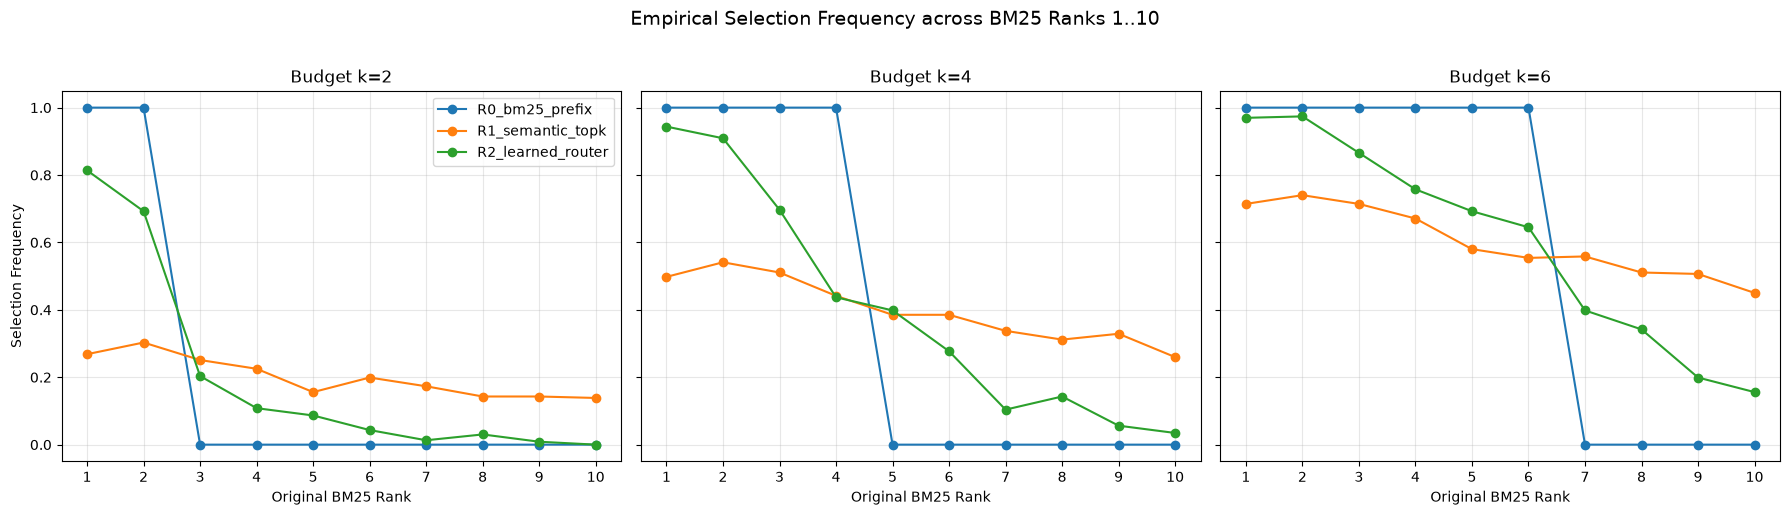

In [12]:
df_rank_dist = compute_selected_rank_distribution(routing_assignments, budgets=BUDGETS)
df_rank_dist.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6_selected_rank_distribution.csv", index=False)
display(df_rank_dist)

# Plot rank distribution
fig, axes = plt.subplots(1, len(BUDGETS), figsize=(18, 5), sharey=True)
ranks = list(range(1, 11))
rank_cols = [f"rank_{r}_freq" for r in ranks]

for idx, k in enumerate(BUDGETS):
    sub = df_rank_dist[df_rank_dist["k"] == k]
    for _, row in sub.iterrows():
        axes[idx].plot(ranks, row[rank_cols].values, marker="o", label=row["router"])
    axes[idx].set_title(f"Budget k={k}", fontsize=12)
    axes[idx].set_xlabel("Original BM25 Rank", fontsize=10)
    axes[idx].set_xticks(ranks)
    axes[idx].grid(True, alpha=0.3)
    if idx == 0:
        axes[idx].set_ylabel("Selection Frequency", fontsize=10)
        axes[idx].legend(loc="upper right")

plt.suptitle("Empirical Selection Frequency across BM25 Ranks 1..10", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w6_selected_rank_distribution.png", dpi=300)
plt.show()


## 13. Routing Diversity & Disagreement Rates

Quantifies whether routers make genuinely different selection decisions:
- Disagreement rate (fraction of queries where selected sets differ)
- Mean Jaccard overlap $\frac{|A \cap B|}{|A \cup B|}$


,k,router_A,router_B,disagreement_rate,mean_jaccard_overlap,n_queries
0,2,R0_bm25_prefix,R1_semantic_topk,0.930736,0.213564,231
1,2,R0_bm25_prefix,R2_learned_router,0.463203,0.681097,231
2,2,R1_semantic_topk,R2_learned_router,0.961039,0.171717,231
3,4,R0_bm25_prefix,R1_semantic_topk,0.952381,0.362152,231
4,4,R0_bm25_prefix,R2_learned_router,0.779221,0.627623,231
5,4,R1_semantic_topk,R2_learned_router,0.978355,0.328551,231
6,6,R0_bm25_prefix,R1_semantic_topk,0.982684,0.513193,231
7,6,R0_bm25_prefix,R2_learned_router,0.826840,0.707277,231
8,6,R1_semantic_topk,R2_learned_router,0.982684,0.494352,231


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


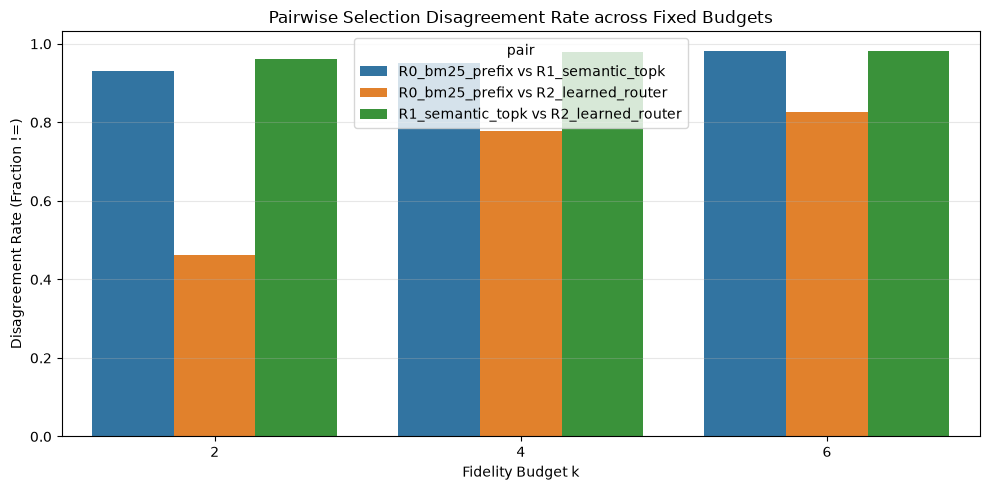

In [13]:
df_diversity = compute_routing_diversity(routing_assignments, budgets=BUDGETS)
df_diversity.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6_routing_diversity.csv", index=False)
display(df_diversity)

# Plot diversity
df_diversity["pair"] = df_diversity["router_A"] + " vs " + df_diversity["router_B"]
plt.figure(figsize=(10, 5))
sns.barplot(data=df_diversity, x="k", y="disagreement_rate", hue="pair")
plt.title("Pairwise Selection Disagreement Rate across Fixed Budgets", fontsize=12)
plt.ylabel("Disagreement Rate (Fraction !=)", fontsize=10)
plt.xlabel("Fidelity Budget k", fontsize=10)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w6_routing_overlap.png", dpi=300)
plt.show()


## 14. Quality vs. Representation Budget Curve

Visualizes the primary quality-context curve for $R_0$, $R_1$, and $R_2$ across fixed budgets $k \in \{2, 4, 6\}$.


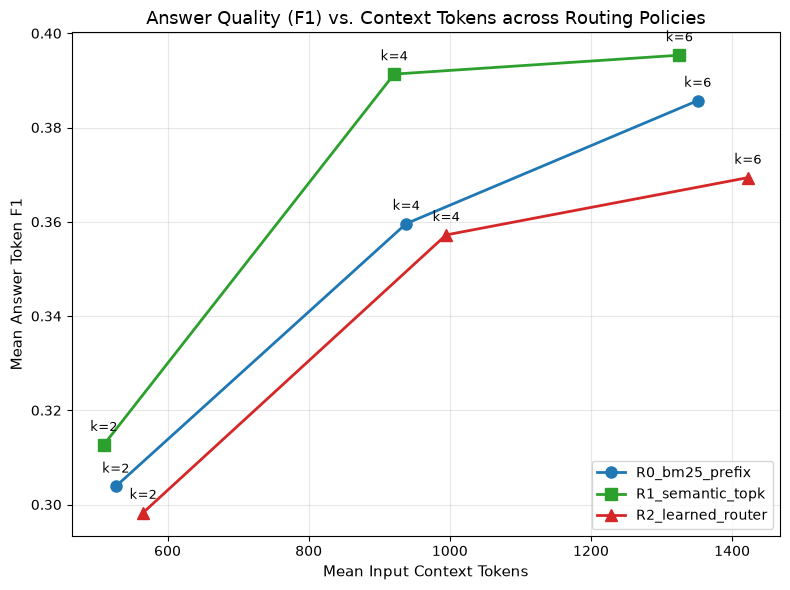

In [14]:
plt.figure(figsize=(8, 6))
palette = {"R0_bm25_prefix": "#1f77b4", "R1_semantic_topk": "#2ca02c", "R2_learned_router": "#d62728"}
markers = {"R0_bm25_prefix": "o", "R1_semantic_topk": "s", "R2_learned_router": "^"}

for r_name in ["R0_bm25_prefix", "R1_semantic_topk", "R2_learned_router"]:
    sub = df_main[df_main["router"] == r_name].sort_values("k")
    plt.plot(
        sub["context_tokens_mean"],
        sub["answer_f1_mean"],
        label=r_name,
        color=palette[r_name],
        marker=markers[r_name],
        linewidth=2,
        markersize=8,
    )
    for _, row in sub.iterrows():
        plt.annotate(
            f"k={int(row['k'])}",
            (row["context_tokens_mean"], row["answer_f1_mean"]),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center",
            fontsize=9,
        )

plt.title("Answer Quality (F1) vs. Context Tokens across Routing Policies", fontsize=13)
plt.xlabel("Mean Input Context Tokens", fontsize=11)
plt.ylabel("Mean Answer Token F1", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w6_quality_vs_budget.png", dpi=300)
plt.show()


## 15. Routing Failure Analysis Table

Identifies specific DEV queries where $R_2 > R_0$ (routing wins) and $R_2 < R_0$ (routing losses).
Examines the chosen ranks and corresponding gold evidence ranks.


In [15]:
k_eval = 4
f1s_r0 = np.array(eval_results["R0_bm25_prefix"][k_eval]["per_query_f1s"])
f1s_r2 = np.array(eval_results["R2_learned_router"][k_eval]["per_query_f1s"])
diffs = f1s_r2 - f1s_r0

top_wins = np.argsort(-diffs)[:5]
top_losses = np.argsort(diffs)[:5]

failure_rows = []
for idx in list(top_wins) + list(top_losses):
    item = dev_items[idx]
    qid = dev_qids[idx]
    gold_ranks = [r + 1 for r, v in enumerate(gold_labels_dev[idx]) if v > 0]
    failure_rows.append({
        "question_id": qid,
        "type": "WIN (R2 > R0)" if diffs[idx] > 0 else "LOSS (R2 < R0)",
        "delta_f1": float(diffs[idx]),
        "f1_R0": float(f1s_r0[idx]),
        "f1_R2": float(f1s_r2[idx]),
        "ranks_R0": [x + 1 for x in routing_assignments["R0_bm25_prefix"][k_eval][idx]],
        "ranks_R2": [x + 1 for x in routing_assignments["R2_learned_router"][k_eval][idx]],
        "gold_evidence_ranks": gold_ranks,
        "question": item["question"][:100] + "...",
    })

df_failures = pd.DataFrame(failure_rows)
df_failures.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6_failure_analysis.csv", index=False)
display(df_failures)


,question_id,type,delta_f1,f1_R0,f1_R2,ranks_R0,ranks_R2,gold_evidence_ranks,question
0,1000,WIN (R2 > R0),1.0,0.0,1.0,"[1, 2, 3, 4]","[1, 2, 3, 9]","[2, 4, 5, 6, 7, 10]",What is English mixed with in the TRAC dataset...
1,917,WIN (R2 > R0),1.0,0.0,1.0,"[1, 2, 3, 4]","[1, 2, 6, 8]","[5, 8, 10]",What languages are seen in the news and TED da...
2,92,WIN (R2 > R0),1.0,0.0,1.0,"[1, 2, 3, 4]","[1, 2, 3, 6]","[1, 2, 3, 5, 6, 7, 8, 10]",Which lexicon-based models did they compare wi...
3,1160,WIN (R2 > R0),1.0,0.0,1.0,"[1, 2, 3, 4]","[2, 3, 4, 6]",[],Is the model compared to a baseline model?...
4,1188,WIN (R2 > R0),1.0,0.0,1.0,"[1, 2, 3, 4]","[1, 2, 4, 5]",[5],Is this software available to the public?...
5,737,LOSS (R2 < R0),-1.0,1.0,0.0,"[1, 2, 3, 4]","[1, 2, 3, 6]",[4],What dataset do they use?...
6,1779,LOSS (R2 < R0),-1.0,1.0,0.0,"[1, 2, 3, 4]","[1, 2, 3, 4]","[2, 3]",How is some information lost in the RNN-based ...
7,1763,LOSS (R2 < R0),-1.0,1.0,0.0,"[1, 2, 3, 4]","[1, 3, 5, 8]","[1, 3, 4, 9]",Did they experiment with the dataset on some t...
8,1909,LOSS (R2 < R0),-1.0,1.0,0.0,"[1, 2, 3, 4]","[1, 2, 3, 4]",[9],What other embedding models are tested?...
9,2015,LOSS (R2 < R0),-1.0,1.0,0.0,"[1, 2, 3, 4]","[1, 2, 3, 5]",[],What are the results achieved from the introdu...


## 16. Optional: $k=2$ Diagnostic Exhaustive Subset Oracle

Guarded by `RUN_SUBSET_ORACLE = False`.
Evaluates all $C(10, 2) = 45$ possible passage pairs on a diagnostic sample of 25 DEV queries to estimate empirical routing headroom.


In [17]:
RUN_SUBSET_ORACLE = True

if RUN_SUBSET_ORACLE:
    print("Executing diagnostic exhaustive subset oracle for k=2 across 25 DEV questions...")
    df_oracle = evaluate_diagnostic_subset_oracle(
        sara_model=sara_model,
        sara_tokenizer=sara_tokenizer,
        dev_records=dev_items,
        cached_embeddings=cached_embeddings,
        k=2,
        sample_size=25,
        device=DEVICE,
    )
    df_oracle.to_csv(Path(cfg["paths"]["oracle_dir"]) / "k2_subset_oracle_results.csv", index=False)
    print(f"Mean R0 F1: {df_oracle['r0_f1'].mean():.4f}")
    print(f"Mean Oracle F1: {df_oracle['oracle_f1'].mean():.4f}")
    print(f"Mean Headroom Delta: {df_oracle['headroom_delta'].mean():.4f}")
    display(df_oracle.head(10))
else:
    print("RUN_SUBSET_ORACLE = False (Skipping expensive exhaustive subset enumeration).")


Executing diagnostic exhaustive subset oracle for k=2 across 25 DEV questions...
Mean R0 F1: 0.2625
Mean Oracle F1: 0.5706
Mean Headroom Delta: 0.3080


,question_id,r0_f1,oracle_f1,headroom_delta,best_ranks,mean_subset_f1,std_subset_f1
0,1000,0.400000,1.000000,0.600000,"[1, 7]",0.306771,0.325213
1,1001,0.142857,0.526316,0.383459,"[2, 6]",0.154300,0.134916
2,1002,0.200000,0.400000,0.200000,"[5, 10]",0.201180,0.085810
3,1003,0.000000,0.000000,0.000000,"[1, 2]",0.000000,0.000000
4,1004,0.000000,0.842105,0.842105,"[1, 4]",0.196104,0.285715
5,1005,0.666667,1.000000,0.333333,"[1, 10]",0.708889,0.267212
6,1013,0.000000,0.285714,0.285714,"[3, 8]",0.022854,0.056717
7,1028,0.000000,1.000000,1.000000,"[1, 3]",0.955556,0.206080
8,1029,0.000000,0.000000,0.000000,"[1, 2]",0.000000,0.000000
9,1030,0.333333,0.400000,0.066667,"[1, 7]",0.221124,0.182990


## 17. Scientific Synthesis & Week 6 Conclusion

### Summary of Hypotheses Tested
1. **Evidence Recall:** Did $R_1$ or $R_2$ successfully identify lower-ranked evidence passages that $R_0$ missed?
2. **Answer Quality:** At identical representation budgets ($k=2, 4, 6$), did selecting better passages translate into higher token $F_1$?
3. **Headroom Interpretation:** Does passage identity routing represent an active frontier for RAG optimization, or is BM25 ranking already near-optimal within the top-10 pool?
